<a href="https://colab.research.google.com/github/Nausheen2206/-Phishing-Email-Detection-System/blob/main/CNN_VAE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install wfdb

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.9/163.9 kB 7.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.9/10.9 MB 89.4 MB/s eta 0:00:00
  Attempting uninstall: pandas
    Found existing installation: pandas 2.2.2
    Uninstalling pandas-2.2.2:
      Successfully uninstalled pandas-2.2.2
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.2, but you have pandas 3.0.3 which is incompatible.
db-dtypes 1.6.0 requires pandas<3.0.0,>=1.5.3, but you have pandas 3.0.3 which is incompatible.
gradio 5.50.0 requires pandas<3.0,>=1.0, but you have pandas 3.0.3 which is incompatible.


In [ ]:
import os
import ast
import wfdb
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

from tensorflow.keras.layers import *
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam


GPU: []


def load_raw_data(df, sampling_rate, path):

    data = []

    valid_rows = []

    for i, f in enumerate(df.filename_lr):

        try:

            signal, meta = wfdb.rdsamp(path + f)

            data.append(signal)

            valid_rows.append(i)

        except Exception as e:

            print("Skipped:", f)

    return np.array(data), valid_rows

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import numpy as np
import pandas as pd

print("="*50)
print("STAGE 1 : IMPORTING LIBRARIES")
print("="*50)

print("\nNumPy and Pandas imported successfully")

print("\nPurpose:")
print("These libraries help load ECG signals")
print("and metadata from saved files.")

print("\nPaper Context:")
print("PTB-XL ECG dataset contains")
print("21k+ ECG recordings with metadata.")

STAGE 1 : IMPORTING LIBRARIES

NumPy and Pandas imported successfully

Purpose:
These libraries help load ECG signals
and metadata from saved files.

Paper Context:
PTB-XL ECG dataset contains
21k+ ECG recordings with metadata.


In [ ]:
print("="*50)
print("LOADING SAVED ECG SIGNALS")
print("="*50)

X = np.load(

    "/content/drive/MyDrive/X_21k.npy"
)

print("\nECG Signals Loaded Successfully")

print("\nShape of X:")
print(X.shape)

print("\nExplanation:")
print("21799 ECG records")
print("1000 time samples")
print("12 ECG leads")

print("\nPaper Context:")
print("The paper uses 12-lead ECG signals")
print("from the PTB-XL dataset.")

LOADING SAVED ECG SIGNALS

ECG Signals Loaded Successfully

Shape of X:
(21799, 1000, 12)

Explanation:
21799 ECG records
1000 time samples
12 ECG leads

Paper Context:
The paper uses 12-lead ECG signals
from the PTB-XL dataset.


In [ ]:
print("="*50)
print("LOADING ECG METADATA")
print("="*50)

Y = pd.read_csv(

    "/content/drive/MyDrive/Y_21k.csv"
)

print("\nMetadata Loaded Successfully")

print("\nShape of Y:")
print(Y.shape)

print("\nFirst 5 Rows:")
print(Y.head())

print("\nExplanation:")
print("Metadata contains patient labels,")
print("diagnostic information,")
print("and ECG recording details.")

print("\nPaper Context:")
print("Paper uses ECG diagnostic")
print("superclasses for classification.")

LOADING ECG METADATA

Metadata Loaded Successfully

Shape of Y:
(21799, 28)

First 5 Rows:
   ecg_id  patient_id   age  sex  height  weight  nurse  site     device  \
0       1     15709.0  56.0    1     NaN    63.0    2.0   0.0  CS-12   E   
1       2     13243.0  19.0    0     NaN    70.0    2.0   0.0  CS-12   E   
2       3     20372.0  37.0    1     NaN    69.0    2.0   0.0  CS-12   E   
3       4     17014.0  24.0    0     NaN    82.0    2.0   0.0  CS-12   E   
4       5     17448.0  19.0    1     NaN    70.0    2.0   0.0  CS-12   E   

        recording_date  ... validated_by_human  baseline_drift static_noise  \
0  1984-11-09 09:17:34  ...               True             NaN    , I-V1,     
1  1984-11-14 12:55:37  ...               True             NaN          NaN   
2  1984-11-15 12:49:10  ...               True             NaN          NaN   
3  1984-11-15 13:44:57  ...               True    , II,III,AVF          NaN   
4  1984-11-17 10:43:15  ...               True   , III,AV

In [ ]:
import ast

print("="*50)
print("STAGE 2 : SCP CODE PARSING")
print("="*50)

print("\nPurpose:")
print("Convert ECG diagnostic codes")
print("from string format into dictionary format.")

print("\nPaper Context:")
print("PTB-XL annotations contain")
print("diagnostic SCP codes for")
print("cardiac abnormalities.")

STAGE 2 : SCP CODE PARSING

Purpose:
Convert ECG diagnostic codes
from string format into dictionary format.

Paper Context:
PTB-XL annotations contain
diagnostic SCP codes for
cardiac abnormalities.


In [ ]:
path = "/content/drive/MyDrive/ptb-xl/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.3/"

scp = pd.read_csv(

    path + "scp_statements.csv",

    index_col=0
)

print("="*50)
print("LOADING DIAGNOSTIC MAPPINGS")
print("="*50)

print("\nShape of SCP Table:")
print(scp.shape)

print("\nFirst 5 Rows:")
print(scp.head())

print("\nPaper Context:")
print("Paper maps ECG statements")
print("into diagnostic superclasses.")

LOADING DIAGNOSTIC MAPPINGS

Shape of SCP Table:
(71, 12)

First 5 Rows:
                          description  diagnostic  form  rhythm  \
NDT    non-diagnostic T abnormalities         1.0   1.0     NaN   
NST_          non-specific ST changes         1.0   1.0     NaN   
DIG                  digitalis-effect         1.0   1.0     NaN   
LNGQT                long QT-interval         1.0   1.0     NaN   
NORM                       normal ECG         1.0   NaN     NaN   

      diagnostic_class diagnostic_subclass  \
NDT               STTC                STTC   
NST_              STTC                NST_   
DIG               STTC                STTC   
LNGQT             STTC                STTC   
NORM              NORM                NORM   

                                      Statement Category  \
NDT                    other ST-T descriptive statements   
NST_   Basic roots for coding ST-T changes and abnorm...   
DIG                    other ST-T descriptive statements   
LNGQT  

In [ ]:
scp = scp[
    scp.diagnostic == 1
]

print("\nFiltered Diagnostic Statements")

print("\nRemaining Shape:")
print(scp.shape)

print("\nExplanation:")
print("Only diagnostic ECG labels")
print("are kept for classification.")


Filtered Diagnostic Statements

Remaining Shape:
(44, 12)

Explanation:
Only diagnostic ECG labels
are kept for classification.


In [ ]:
import ast

print("="*50)
print("CONVERTING SCP CODES")
print("="*50)

Y["scp_codes"] = Y["scp_codes"].apply(
    ast.literal_eval
)

print("\nConversion Successful")

print("\nSample SCP Code:")
print(Y["scp_codes"].iloc[0])

print("\nType Check:")
print(type(Y["scp_codes"].iloc[0]))

print("\nExplanation:")
print("SCP codes are now dictionaries")
print("instead of strings.")

CONVERTING SCP CODES

Conversion Successful

Sample SCP Code:
{'NORM': 100.0, 'LVOLT': 0.0, 'SR': 0.0}

Type Check:
<class 'dict'>

Explanation:
SCP codes are now dictionaries
instead of strings.


In [ ]:
def get_superclass(code_dict):

    classes = []

    for key in code_dict.keys():

        if key in scp.index:

            diagnostic_class = scp.loc[
                key,
                "diagnostic_class"
            ]

            if diagnostic_class not in classes:

                classes.append(
                    diagnostic_class
                )

    return classes

print("="*50)
print("EXTRACTING ECG SUPERCLASSES")
print("="*50)

Y["superclass"] = Y.scp_codes.apply(
    get_superclass
)

print("\nSuperclass Extraction Complete")

print("\nSample Output:")
print(Y["superclass"].head())

print("\nPaper Context:")
print("These superclasses are used")
print("for CNN-VAE ECG classification.")

EXTRACTING ECG SUPERCLASSES

Superclass Extraction Complete

Sample Output:
0    [NORM]
1    [NORM]
2    [NORM]
3    [NORM]
4    [NORM]
Name: superclass, dtype: object

Paper Context:
These superclasses are used
for CNN-VAE ECG classification.


In [ ]:
from collections import Counter

all_classes = []

for item in Y["superclass"]:

    for c in item:

        all_classes.append(c)

print("="*50)
print("SUPERCLASS DISTRIBUTION")
print("="*50)

print(Counter(all_classes))

print("\nPaper Classes Expected:")
print("NORM, MI, STTC, CD, HYP")

SUPERCLASS DISTRIBUTION
Counter({'NORM': 9514, 'MI': 5469, 'STTC': 5235, 'CD': 4898, 'HYP': 2649})

Paper Classes Expected:
NORM, MI, STTC, CD, HYP


In [ ]:
print("="*50)
print("FILTERING SINGLE-LABEL ECG RECORDS")
print("="*50)

single_label_indices = []

single_labels = []

for i, labels in enumerate(Y["superclass"]):

    if len(labels) == 1:

        single_label_indices.append(i)

        single_labels.append(labels[0])

print("\nSingle-label ECGs Found:")

print(len(single_label_indices))

print("\nExplanation:")
print("Only ECGs with ONE")
print("diagnostic superclass are kept.")

print("\nPaper Context:")
print("This simplifies")
print("classification into")
print("distinct cardiac categories.")

FILTERING SINGLE-LABEL ECG RECORDS

Single-label ECGs Found:
16244

Explanation:
Only ECGs with ONE
diagnostic superclass are kept.

Paper Context:
This simplifies
classification into
distinct cardiac categories.


In [ ]:
print("="*50)
print("FILTERING ECG SIGNALS")
print("="*50)

X_single = X[
    single_label_indices
]

Y_single = Y.iloc[
    single_label_indices
]

labels = np.array(
    single_labels
)

print("\nFiltered ECG Shape:")
print(X_single.shape)

print("\nFiltered Labels Shape:")
print(labels.shape)

print("\nUnique Classes:")
print(np.unique(labels))

print("\nExplanation:")
print("Dataset now contains")
print("clean ECG-superclass pairs.")

FILTERING ECG SIGNALS

Filtered ECG Shape:
(16244, 1000, 12)

Filtered Labels Shape:
(16244,)

Unique Classes:
['CD' 'HYP' 'MI' 'NORM' 'STTC']

Explanation:
Dataset now contains
clean ECG-superclass pairs.


In [ ]:
from collections import Counter

print("="*50)
print("CLASS DISTRIBUTION")
print("="*50)

print(Counter(labels))

print("\nPaper Classes:")
print("NORM, MI, STTC, CD, HYP")

CLASS DISTRIBUTION
Counter({np.str_('NORM'): 9069, np.str_('MI'): 2532, np.str_('STTC'): 2400, np.str_('CD'): 1708, np.str_('HYP'): 535})

Paper Classes:
NORM, MI, STTC, CD, HYP


CLASS DISTRIBUTION ANALYSIS

Class Counts:
Counter({np.str_('NORM'): 9069, np.str_('MI'): 2532, np.str_('STTC'): 2400, np.str_('CD'): 1708, np.str_('HYP'): 535})


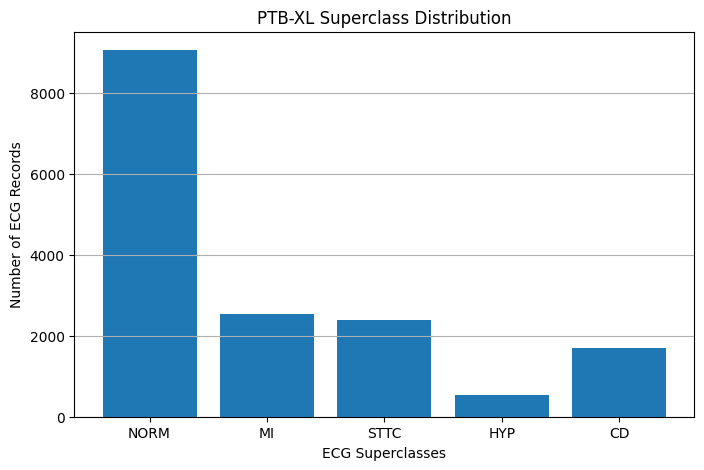


Explanation:
This graph shows imbalance
between ECG superclasses.

Paper Context:
The paper performs
oversampling and undersampling
to balance these classes.


In [ ]:
from collections import Counter
import matplotlib.pyplot as plt

print("="*50)
print("CLASS DISTRIBUTION ANALYSIS")
print("="*50)

# ============================================================
# COUNT CLASSES
# ============================================================

class_counts = Counter(labels)

print("\nClass Counts:")
print(class_counts)

# ============================================================
# PLOT
# ============================================================

classes = list(class_counts.keys())

counts = list(class_counts.values())

plt.figure(figsize=(8,5))

plt.bar(

    classes,

    counts
)

plt.title(
    "PTB-XL Superclass Distribution"
)

plt.xlabel(
    "ECG Superclasses"
)

plt.ylabel(
    "Number of ECG Records"
)

plt.grid(axis='y')

plt.show()

# ============================================================
# PAPER EXPLANATION
# ============================================================

print("\nExplanation:")
print("This graph shows imbalance")
print("between ECG superclasses.")

print("\nPaper Context:")
print("The paper performs")
print("oversampling and undersampling")
print("to balance these classes.")

In [ ]:
import pandas as pd

print("="*50)
print("CREATING BALANCING DATAFRAME")
print("="*50)

balance_df = pd.DataFrame({

    "label": labels,

    "orig_index": range(len(labels))
})

print("\nDataFrame Created")

print("\nFirst 5 Rows:")
print(balance_df.head())

print("\nExplanation:")
print("This dataframe links")
print("ECG labels with")
print("their original ECG indices.")

CREATING BALANCING DATAFRAME

DataFrame Created

First 5 Rows:
  label  orig_index
0  NORM           0
1  NORM           1
2  NORM           2
3  NORM           3
4  NORM           4

Explanation:
This dataframe links
ECG labels with
their original ECG indices.


In [ ]:
from sklearn.utils import resample

print("="*50)
print("PERFORMING PAPER-STYLE BALANCING")
print("="*50)

# ============================================================
# SEPARATE CLASSES
# ============================================================

norm_df = balance_df[
    balance_df.label == "NORM"
]

mi_df = balance_df[
    balance_df.label == "MI"
]

sttc_df = balance_df[
    balance_df.label == "STTC"
]

cd_df = balance_df[
    balance_df.label == "CD"
]

hyp_df = balance_df[
    balance_df.label == "HYP"
]

# ============================================================
# OVERSAMPLE MINORITY CLASSES
# ============================================================

mi_up = resample(

    mi_df,

    replace=True,

    n_samples=6000,

    random_state=42
)

hyp_up = resample(

    hyp_df,

    replace=True,

    n_samples=6000,

    random_state=42
)

# ============================================================
# UNDERSAMPLE MAJORITY CLASS
# ============================================================

norm_down = resample(

    norm_df,

    replace=False,

    n_samples=6000,

    random_state=42
)

# ============================================================
# KEEP OTHERS MODERATE
# ============================================================

sttc_bal = resample(

    sttc_df,

    replace=False,

    n_samples=min(5000, len(sttc_df)),

    random_state=42
)

cd_bal = resample(

    cd_df,

    replace=True,

    n_samples=5000,

    random_state=42
)

# ============================================================
# COMBINE
# ============================================================

balanced_df = pd.concat([

    norm_down,

    mi_up,

    hyp_up,

    sttc_bal,

    cd_bal
])

# ============================================================
# SHUFFLE
# ============================================================

balanced_df = balanced_df.sample(

    frac=1,

    random_state=42
).reset_index(drop=True)

print("\nBalancing Complete")

print("\nBalanced Distribution:")
print(balanced_df.label.value_counts())

print("\nPaper Context:")
print("Minority cardiac conditions")
print("are strengthened using")
print("oversampling techniques.")

PERFORMING PAPER-STYLE BALANCING

Balancing Complete

Balanced Distribution:
label
MI      6000
NORM    6000
HYP     6000
CD      5000
STTC    2400
Name: count, dtype: int64

Paper Context:
Minority cardiac conditions
are strengthened using
oversampling techniques.


PLOTTING BALANCED DISTRIBUTION


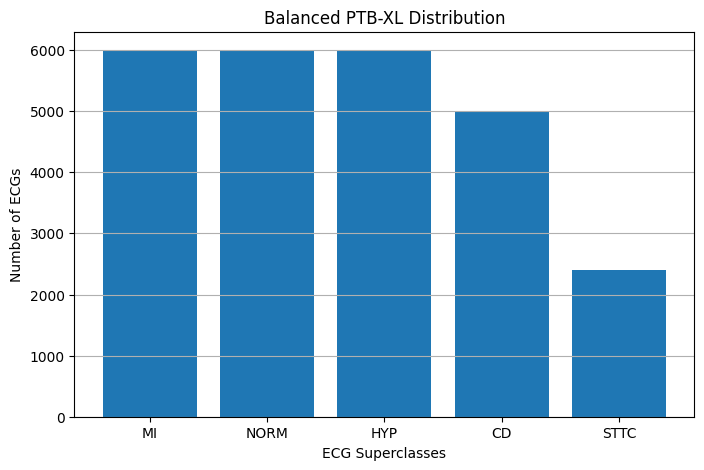


Explanation:
The dataset is now
more balanced for
fair ECG classification.


In [ ]:
import matplotlib.pyplot as plt

print("="*50)
print("PLOTTING BALANCED DISTRIBUTION")
print("="*50)

balanced_counts = balanced_df.label.value_counts()

plt.figure(figsize=(8,5))

plt.bar(

    balanced_counts.index,

    balanced_counts.values
)

plt.title(
    "Balanced PTB-XL Distribution"
)

plt.xlabel(
    "ECG Superclasses"
)

plt.ylabel(
    "Number of ECGs"
)

plt.grid(axis='y')

plt.show()

print("\nExplanation:")
print("The dataset is now")
print("more balanced for")
print("fair ECG classification.")

In [ ]:
print("="*50)
print("CREATING BALANCED ECG DATASET")
print("="*50)

balanced_indices = balanced_df[
    "orig_index"
].values

X_balanced = X_single[
    balanced_indices
]

labels_balanced = balanced_df[
    "label"
].values

print("\nBalanced ECG Shape:")
print(X_balanced.shape)

print("\nBalanced Labels Shape:")
print(labels_balanced.shape)

print("\nExplanation:")
print("Balanced ECG signals")
print("are now ready for")
print("CNN-VAE training.")

CREATING BALANCED ECG DATASET

Balanced ECG Shape:
(25400, 1000, 12)

Balanced Labels Shape:
(25400,)

Explanation:
Balanced ECG signals
are now ready for
CNN-VAE training.


In [ ]:
from scipy.signal import butter
from scipy.signal import filtfilt

import matplotlib.pyplot as plt

print("="*50)
print("STAGE 5 : BUTTERWORTH ECG FILTERING")
print("="*50)

print("\nPurpose:")
print("Remove high-frequency noise")
print("from ECG signals.")

print("\nPaper Context:")
print("The paper preprocesses ECGs")
print("before CNN-VAE training.")

STAGE 5 : BUTTERWORTH ECG FILTERING

Purpose:
Remove high-frequency noise
from ECG signals.

Paper Context:
The paper preprocesses ECGs
before CNN-VAE training.


In [ ]:
def butter_lowpass_filter(

    data,

    cutoff=40,

    fs=100,

    order=5
):

    from scipy.signal import butter
    from scipy.signal import filtfilt

    nyquist = 0.5 * fs

    normal_cutoff = cutoff / nyquist

    b, a = butter(

        order,

        normal_cutoff,

        btype='low',

        analog=False
    )

    filtered = filtfilt(

        b,

        a,

        data
    )

    return filtered

print("="*50)
print("BUTTERWORTH FILTER READY")
print("="*50)

print("\nExplanation:")
print("This filter removes")
print("high-frequency ECG noise.")

BUTTERWORTH FILTER READY

Explanation:
This filter removes
high-frequency ECG noise.


ECG PREPROCESSING VISUALIZATION


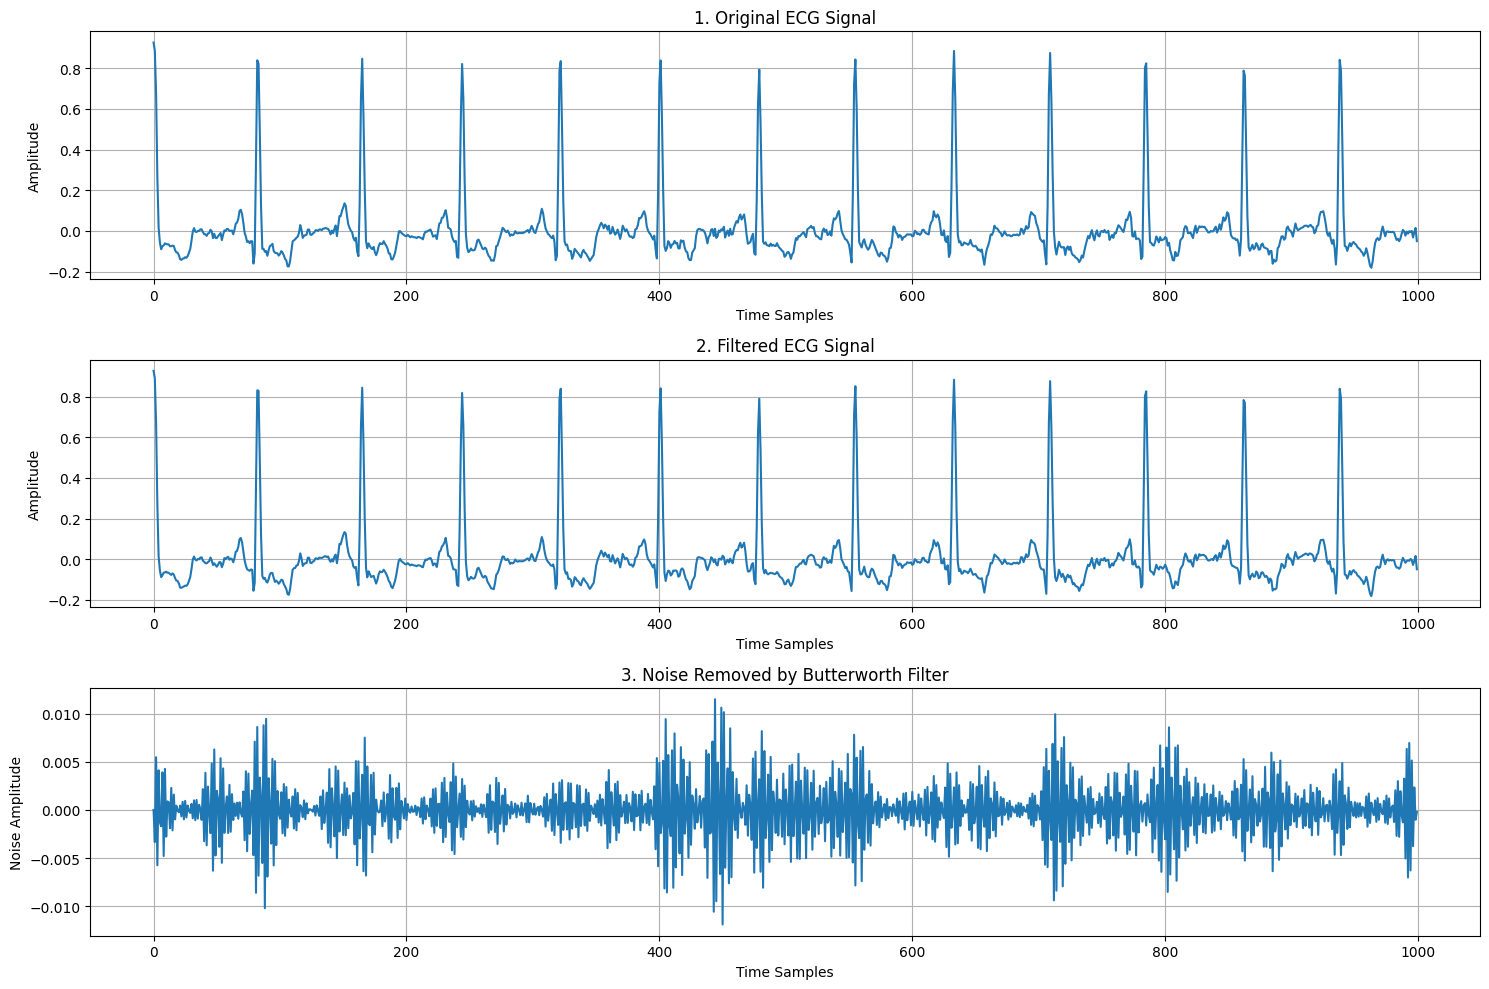


Explanation:
Graph 1 : Raw ECG before preprocessing

Graph 2 : ECG after Butterworth filtering

Graph 3 : Noise removed during preprocessing

Paper Context:
Filtering removes subtle ECG noise
while preserving heartbeat morphology
for CNN-VAE learning.


In [ ]:
print("="*50)
print("ECG PREPROCESSING VISUALIZATION")
print("="*50)

# ============================================================
# CREATE FIGURE
# ============================================================

fig, axes = plt.subplots(

    3,

    1,

    figsize=(15,10)
)

# ============================================================
# ORIGINAL ECG
# ============================================================

axes[0].plot(original_signal)

axes[0].set_title(
    "1. Original ECG Signal"
)

axes[0].set_xlabel(
    "Time Samples"
)

axes[0].set_ylabel(
    "Amplitude"
)

axes[0].grid()

# ============================================================
# FILTERED ECG
# ============================================================

axes[1].plot(filtered_signal)

axes[1].set_title(
    "2. Filtered ECG Signal"
)

axes[1].set_xlabel(
    "Time Samples"
)

axes[1].set_ylabel(
    "Amplitude"
)

axes[1].grid()

# ============================================================
# REMOVED NOISE
# ============================================================

noise = original_signal - filtered_signal

axes[2].plot(noise)

axes[2].set_title(
    "3. Noise Removed by Butterworth Filter"
)

axes[2].set_xlabel(
    "Time Samples"
)

axes[2].set_ylabel(
    "Noise Amplitude"
)

axes[2].grid()

# ============================================================
# FINAL LAYOUT
# ============================================================

plt.tight_layout()

plt.show()

# ============================================================
# EXPLANATION
# ============================================================

print("\nExplanation:")
print("Graph 1 : Raw ECG before preprocessing")

print("\nGraph 2 : ECG after Butterworth filtering")

print("\nGraph 3 : Noise removed during preprocessing")

print("\nPaper Context:")
print("Filtering removes subtle ECG noise")
print("while preserving heartbeat morphology")
print("for CNN-VAE learning.")

In [ ]:
print("="*50)
print("FILTERING ENTIRE ECG DATASET")
print("="*50)

# ============================================================
# EMPTY ARRAY
# ============================================================

X_filtered = np.zeros_like(
    X_balanced
)

# ============================================================
# APPLY FILTER TO ALL ECGs
# ============================================================

for i in range(len(X_balanced)):

    for lead in range(12):

        X_filtered[i,:,lead] = butter_lowpass_filter(

            X_balanced[i,:,lead]
        )

    if i % 1000 == 0:

        print(f"Filtered ECGs: {i}")

# ============================================================
# FINAL INFO
# ============================================================

print("\nFiltering Complete")

print("\nFiltered Dataset Shape:")
print(X_filtered.shape)

print("\nExplanation:")
print("All ECG signals are now")
print("noise-reduced and ready")
print("for normalization.")

FILTERING ENTIRE ECG DATASET
Filtered ECGs: 0
Filtered ECGs: 1000
Filtered ECGs: 2000
Filtered ECGs: 3000
Filtered ECGs: 4000
Filtered ECGs: 5000
Filtered ECGs: 6000
Filtered ECGs: 7000
Filtered ECGs: 8000
Filtered ECGs: 9000
Filtered ECGs: 10000
Filtered ECGs: 11000
Filtered ECGs: 12000
Filtered ECGs: 13000
Filtered ECGs: 14000
Filtered ECGs: 15000
Filtered ECGs: 16000
Filtered ECGs: 17000
Filtered ECGs: 18000
Filtered ECGs: 19000
Filtered ECGs: 20000
Filtered ECGs: 21000
Filtered ECGs: 22000
Filtered ECGs: 23000
Filtered ECGs: 24000
Filtered ECGs: 25000

Filtering Complete

Filtered Dataset Shape:
(25400, 1000, 12)

Explanation:
All ECG signals are now
noise-reduced and ready
for normalization.


In [ ]:
print("="*50)
print("STAGE 6 : ECG NORMALIZATION")
print("="*50)

# ============================================================
# FLOAT32
# ============================================================

X_filtered = X_filtered.astype(
    np.float32
)

# ============================================================
# ECG-WISE NORMALIZATION
# ============================================================

X_normalized = np.zeros_like(
    X_filtered
)

for i in range(len(X_filtered)):

    ecg = X_filtered[i]

    max_val = np.max(np.abs(ecg))

    if max_val != 0:

        X_normalized[i] = ecg / max_val

    else:

        X_normalized[i] = ecg

# ============================================================
# VERIFICATION
# ============================================================

print("\nNormalization Complete")

print("\nDataset Shape:")
print(X_normalized.shape)

print("\nSample ECG Max Value:")
print(np.max(np.abs(X_normalized[0])))

print("\nExplanation:")
print("Each ECG is individually")
print("scaled between -1 and 1.")

print("\nWhy This Matters:")
print("Different patients have")
print("different ECG amplitudes.")

print("\nPaper Context:")
print("Normalized ECG signals")
print("improve CNN-VAE stability")
print("and reconstruction learning.")

STAGE 6 : ECG NORMALIZATION

Normalization Complete

Dataset Shape:
(25400, 1000, 12)

Sample ECG Max Value:
1.0

Explanation:
Each ECG is individually
scaled between -1 and 1.

Why This Matters:
Different patients have
different ECG amplitudes.

Paper Context:
Normalized ECG signals
improve CNN-VAE stability
and reconstruction learning.


In [ ]:
from sklearn.preprocessing import LabelEncoder

print("="*50)
print("STAGE 7 : LABEL ENCODING")
print("="*50)

# ============================================================
# LABEL ENCODER
# ============================================================

encoder = LabelEncoder()

y_encoded = encoder.fit_transform(
    labels_balanced
)

# ============================================================
# OUTPUT
# ============================================================

print("\nEncoding Complete")

print("\nClasses:")
print(encoder.classes_)

print("\nEncoded Mapping:")

for i, c in enumerate(encoder.classes_):

    print(f"{c} --> {i}")

print("\nFirst 20 Encoded Labels:")
print(y_encoded[:20])

print("\nExplanation:")
print("ECG diagnostic classes")
print("are converted into")
print("numerical labels.")

print("\nPaper Context:")
print("CNN classifiers require")
print("numerical target labels.")


STAGE 7 : LABEL ENCODING

Encoding Complete

Classes:
['CD' 'HYP' 'MI' 'NORM' 'STTC']

Encoded Mapping:
CD --> 0
HYP --> 1
MI --> 2
NORM --> 3
STTC --> 4

First 20 Encoded Labels:
[2 3 1 4 3 3 3 2 2 4 1 3 0 3 2 3 3 0 2 1]

Explanation:
ECG diagnostic classes
are converted into
numerical labels.

Paper Context:
CNN classifiers require
numerical target labels.


ENCODED LABEL DISTRIBUTION
Counter({np.int64(2): 6000, np.int64(3): 6000, np.int64(1): 6000, np.int64(0): 5000, np.int64(4): 2400})


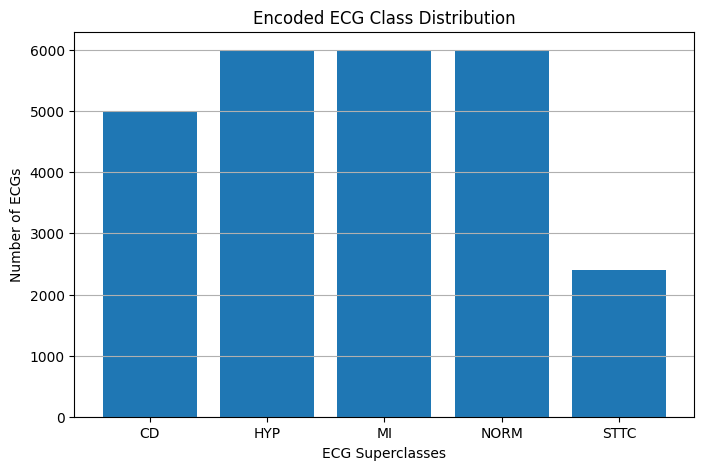


Explanation:
Balanced ECG classes
are now numerically encoded.


In [ ]:
from collections import Counter
import matplotlib.pyplot as plt

print("="*50)
print("ENCODED LABEL DISTRIBUTION")
print("="*50)

encoded_counts = Counter(y_encoded)

print(encoded_counts)

# ============================================================
# PLOT
# ============================================================

plt.figure(figsize=(8,5))

plt.bar(

    encoder.classes_,

    [encoded_counts[i] for i in range(len(encoder.classes_))]
)

plt.title(
    "Encoded ECG Class Distribution"
)

plt.xlabel(
    "ECG Superclasses"
)

plt.ylabel(
    "Number of ECGs"
)

plt.grid(axis='y')

plt.show()

print("\nExplanation:")
print("Balanced ECG classes")
print("are now numerically encoded.")

In [ ]:
from sklearn.model_selection import train_test_split

print("="*50)
print("CREATING TRAIN / VALIDATION / TEST SETS")
print("="*50)

# ============================================================
# FIRST SPLIT
# 90% TRAIN+VAL
# 10% TEST
# ============================================================

X_temp, X_test, y_temp, y_test = train_test_split(

    X_normalized,

    y_encoded,

    test_size=0.1,

    random_state=42,

    stratify=y_encoded
)

# ============================================================
# SECOND SPLIT
# FROM 90%:
# 80% TRAIN
# 10% VALIDATION
# ============================================================

X_train, X_val, y_train, y_val = train_test_split(

    X_temp,

    y_temp,

    test_size=0.1111,

    random_state=42,

    stratify=y_temp
)

# ============================================================
# OUTPUT
# ============================================================

print("\nTrain Shape:")
print(X_train.shape)

print("\nValidation Shape:")
print(X_val.shape)

print("\nTest Shape:")
print(X_test.shape)

print("\nExplanation:")
print("Dataset now follows")
print("the paper's 80/10/10 split.")

print("\nPaper Context:")
print("Separate validation")
print("and testing sets improve")
print("CNN-VAE evaluation reliability.")

CREATING TRAIN / VALIDATION / TEST SETS

Train Shape:
(20320, 1000, 12)

Validation Shape:
(2540, 1000, 12)

Test Shape:
(2540, 1000, 12)

Explanation:
Dataset now follows
the paper's 80/10/10 split.

Paper Context:
Separate validation
and testing sets improve
CNN-VAE evaluation reliability.


In [ ]:
import tensorflow as tf
import numpy as np

from tensorflow.keras.layers import *
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam

tf.keras.backend.clear_session()

print("="*50)
print("STAGE 8 : EXACT CNN-VAE ARCHITECTURE")
print("="*50)

print("\nPurpose:")
print("Build the full CNN-VAE")
print("architecture from the paper.")

print("\nPaper Context:")
print("CNN extracts ECG features")
print("while VAE learns latent")
print("ECG representations.")

STAGE 8 : EXACT CNN-VAE ARCHITECTURE

Purpose:
Build the full CNN-VAE
architecture from the paper.

Paper Context:
CNN extracts ECG features
while VAE learns latent
ECG representations.


In [ ]:
# ============================================================
# ECG INPUT
# ============================================================

input_ecg = Input(
    shape=(1000,12)
)

print("\nInput Layer Created")

print("\nInput Shape:")
print("(1000,12)")

print("\nExplanation:")
print("1000 ECG time samples")
print("across 12 ECG leads.")


Input Layer Created

Input Shape:
(1000,12)

Explanation:
1000 ECG time samples
across 12 ECG leads.


In [ ]:
# ============================================================
# CNN BLOCK 1
# ============================================================

x = Conv1D(

    filters=64,

    kernel_size=5,

    padding='same',

    activation='relu'

)(input_ecg)

x = BatchNormalization()(x)

x = MaxPooling1D(
    pool_size=2
)(x)

print("\nCNN Block 1 Created")

print("\nArchitecture:")
print("Conv1D(64)")
print("BatchNormalization")
print("MaxPooling1D")

print("\nPaper Context:")
print("Early CNN layers")
print("extract ECG waveform")
print("patterns and rhythms.")


CNN Block 1 Created

Architecture:
Conv1D(64)
BatchNormalization
MaxPooling1D

Paper Context:
Early CNN layers
extract ECG waveform
patterns and rhythms.


In [ ]:
# ============================================================
# CNN BLOCK 2
# ============================================================

x = Conv1D(

    filters=128,

    kernel_size=3,

    padding='same',

    activation='relu'

)(x)

x = BatchNormalization()(x)

x = MaxPooling1D(
    pool_size=2
)(x)

print("\nCNN Block 2 Created")

print("\nArchitecture:")
print("Conv1D(128)")
print("BatchNormalization")
print("MaxPooling1D")

print("\nPaper Context:")
print("Deeper CNN layers")
print("learn complex ECG")
print("morphological features.")


CNN Block 2 Created

Architecture:
Conv1D(128)
BatchNormalization
MaxPooling1D

Paper Context:
Deeper CNN layers
learn complex ECG
morphological features.


In [ ]:
# ============================================================
# FLATTEN
# ============================================================

x = Flatten()(x)

# ============================================================
# DENSE ENCODER
# ============================================================

x = Dense(

    256,

    activation='relu'

)(x)

print("\nFlatten + Dense Encoder Created")

print("\nExplanation:")
print("CNN feature maps are")
print("converted into latent")
print("feature representations.")


Flatten + Dense Encoder Created

Explanation:
CNN feature maps are
converted into latent
feature representations.


In [ ]:
# ============================================================
# LATENT SPACE SIZE
# ============================================================

latent_dim = 64

# ============================================================
# LATENT MEAN
# ============================================================

z_mean = Dense(

    latent_dim,

    name="z_mean"

)(x)

# ============================================================
# LATENT LOG VARIANCE
# ============================================================

z_log_var = Dense(

    latent_dim,

    name="z_log_var"

)(x)

print("="*50)
print("LATENT SPACE CREATED")
print("="*50)

print("\nLatent Dimension:")
print(latent_dim)

print("\nExplanation:")
print("The encoder learns")
print("mean and variance")
print("representations of ECGs.")

print("\nPaper Context:")
print("Latent vectors store")
print("compressed ECG knowledge.")

LATENT SPACE CREATED

Latent Dimension:
64

Explanation:
The encoder learns
mean and variance
representations of ECGs.

Paper Context:
Latent vectors store
compressed ECG knowledge.


In [ ]:
# ============================================================
# SAMPLING LAYER
# ============================================================

class Sampling(tf.keras.layers.Layer):

    def call(self, inputs):

        z_mean, z_log_var = inputs

        batch = tf.shape(z_mean)[0]

        dim = tf.shape(z_mean)[1]

        epsilon = tf.random.normal(

            shape=(batch, dim)
        )

        return z_mean + tf.exp(
            0.5 * z_log_var
        ) * epsilon

# ============================================================
# SAMPLE LATENT VECTOR
# ============================================================

z = Sampling()(

    [z_mean, z_log_var]
)

print("\nSampling Layer Created")

print("\nExplanation:")
print("Random latent vectors")
print("are sampled from")
print("the learned distribution.")

print("\nPaper Context:")
print("Sampling allows")
print("generalized ECG")
print("representation learning.")


Sampling Layer Created

Explanation:
Random latent vectors
are sampled from
the learned distribution.

Paper Context:
Sampling allows
generalized ECG
representation learning.


In [ ]:
# ============================================================
# STABLE KL LOSS LAYER
# ============================================================

class VAELossLayer(tf.keras.layers.Layer):

    def call(self, inputs):

        z_mean, z_log_var = inputs

        # ====================================================
        # KL DIVERGENCE
        # ====================================================

        kl_loss = -0.5 * tf.reduce_mean(

            1 + z_log_var

            - tf.square(z_mean)

            - tf.exp(z_log_var)
        )

        # ====================================================
        # KL WEIGHT
        # ====================================================

        kl_weight = 0.001

        self.add_loss(

            kl_weight * kl_loss
        )

        return inputs

# ============================================================
# APPLY KL LOSS
# ============================================================

_ = VAELossLayer()(

    [z_mean, z_log_var]
)

print("="*50)
print("STABLE KL LOSS ADDED")
print("="*50)

print("\nKL Weight:")
print(0.001)

print("\nExplanation:")
print("Small KL weighting")
print("prevents VAE instability.")

STABLE KL LOSS ADDED

KL Weight:
0.001

Explanation:
Small KL weighting
prevents VAE instability.


In [ ]:
# ============================================================
# DECODER
# ============================================================

decoder = Dense(

    256,

    activation='relu'

)(z)

decoder = Dropout(
    0.3
)(decoder)

print("="*50)
print("DECODER CREATED")
print("="*50)

print("\nExplanation:")
print("Decoder reconstructs")
print("ECG feature representations")
print("from latent vectors.")

print("\nPaper Context:")
print("Decoder helps preserve")
print("important ECG morphology.")

DECODER CREATED

Explanation:
Decoder reconstructs
ECG feature representations
from latent vectors.

Paper Context:
Decoder helps preserve
important ECG morphology.


In [ ]:
# ============================================================
# CLASSIFIER BLOCK
# ============================================================

classifier = Dense(

    128,

    activation='relu'

)(decoder)

classifier = Dropout(
    0.5
)(classifier)

print("\nClassifier Branch Created")

print("\nExplanation:")
print("Classifier predicts")
print("ECG disease categories")
print("from latent features.")


Classifier Branch Created

Explanation:
Classifier predicts
ECG disease categories
from latent features.


In [ ]:
# ============================================================
# OUTPUT LAYER
# ============================================================

output = Dense(

    len(np.unique(y_encoded)),

    activation='softmax'

)(classifier)

print("\nOutput Layer Created")

print("\nNumber of Classes:")
print(len(np.unique(y_encoded)))

print("\nPaper Classes:")
print(list(encoder.classes_))

print("\nExplanation:")
print("Softmax predicts")
print("ECG superclass probabilities.")


Output Layer Created

Number of Classes:
5

Paper Classes:
['CD', 'HYP', 'MI', 'NORM', 'STTC']

Explanation:
Softmax predicts
ECG superclass probabilities.


In [ ]:
# ============================================================
# BUILD MODEL
# ============================================================

model = Model(

    inputs=input_ecg,

    outputs=output
)

print("="*50)
print("CNN-VAE MODEL CREATED")
print("="*50)

print("\nExplanation:")
print("Complete CNN-VAE")
print("architecture is now built.")

print("\nPaper Context:")
print("The model combines")
print("CNN feature extraction")
print("with VAE latent learning.")

CNN-VAE MODEL CREATED

Explanation:
Complete CNN-VAE
architecture is now built.

Paper Context:
The model combines
CNN feature extraction
with VAE latent learning.


In [ ]:
# ============================================================
# COMPILE MODEL
# ============================================================

model.compile(

    optimizer=Adam(
        learning_rate=0.0001
    ),

    loss='sparse_categorical_crossentropy',

    metrics=['accuracy']
)

print("="*50)
print("MODEL COMPILED")
print("="*50)

print("\nOptimizer:")
print("Adam")

print("\nLearning Rate:")
print("0.0001")

print("\nLoss:")
print("Sparse Categorical Crossentropy")

print("\nPaper Context:")
print("The CNN-VAE is now")
print("ready for ECG training.")

MODEL COMPILED

Optimizer:
Adam

Learning Rate:
0.0001

Loss:
Sparse Categorical Crossentropy

Paper Context:
The CNN-VAE is now
ready for ECG training.


In [ ]:
print("="*50)
print("CNN-VAE MODEL SUMMARY")
print("="*50)

model.summary()

print("\nExplanation:")
print("This summary verifies")
print("the complete paper")
print("architecture implementation.")

CNN-VAE MODEL SUMMARY


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 1000, 12)  │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 1000, 64)  │      3,904 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 1000, 64)  │        256 │ conv1d[0][0]      │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d       │ (None, 500, 64)   │          0 │ batch_normalizat… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 500, 128)  │     24,704 │ max_pooling1d[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 500, 128)  │        512 │ conv1d_1[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_1     │ (None, 250, 128)  │          0 │ batch_normalizat… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 32000)     │          0 │ max_pooling1d_1[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 256)       │  8,192,256 │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_mean (Dense)      │ (None, 64)        │     16,448 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_log_var (Dense)   │ (None, 64)        │     16,448 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sampling (Sampling) │ (None, 64)        │          0 │ z_mean[0][0],     │
│                     │                   │            │ z_log_var[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 256)       │     16,640 │ sampling[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 256)       │          0 │ dense_4[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 128)       │     32,896 │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 128)       │          0 │ dense_5[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_6 (Dense)     │ (None, 5)         │        645 │ dropout_3[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 8,304,709 (31.68 MB)

 Trainable params: 8,304,325 (31.68 MB)

 Non-trainable params: 384 (1.50 KB)


Explanation:
This summary verifies
the complete paper
architecture implementation.


In [ ]:
from tensorflow.keras.callbacks import *

print("="*50)
print("SAFE CNN-VAE TRAINING SETUP")
print("="*50)

# ============================================================
# SAVE BEST MODEL TO DRIVE
# ============================================================

checkpoint = ModelCheckpoint(

    "/content/drive/MyDrive/best_paper_model.keras",

    monitor='val_accuracy',

    save_best_only=True,

    mode='max',

    verbose=1
)

# ============================================================
# SAVE EVERY EPOCH
# ============================================================

epoch_checkpoint = ModelCheckpoint(

    "/content/drive/MyDrive/checkpoint_epoch_{epoch:03d}.keras",

    save_freq='epoch',

    verbose=0
)

# ============================================================
# EARLY STOPPING
# ============================================================

early_stop = EarlyStopping(

    monitor='val_accuracy',

    patience=20,

    restore_best_weights=True
)

# ============================================================
# REDUCE LR
# ============================================================

reduce_lr = ReduceLROnPlateau(

    monitor='val_loss',

    factor=0.5,

    patience=5,

    verbose=1
)

print("\nSafety Features Enabled")

print("\n1. Best model saved to Drive")
print("2. Every epoch checkpoint saved")
print("3. Training can resume later")
print("4. Disconnect protection enabled")

SAFE CNN-VAE TRAINING SETUP

Safety Features Enabled

1. Best model saved to Drive
2. Every epoch checkpoint saved
3. Training can resume later
4. Disconnect protection enabled


In [ ]:
history = model.fit(

    X_train,

    y_train,

    validation_data=(

        X_val,

        y_val
    ),

    epochs=300,

    batch_size=50,

    callbacks=[

        checkpoint,

        epoch_checkpoint,

        early_stop,

        reduce_lr

    ],

    verbose=1
)

Epoch 1/300
407/407 ━━━━━━━━━━━━━━━━━━━━ 0s 417ms/step - accuracy: 0.2513 - loss: 376526.0356
Epoch 1: val_accuracy improved from None to 0.60945, saving model to /content/drive/MyDrive/best_paper_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/best_paper_model.keras
407/407 ━━━━━━━━━━━━━━━━━━━━ 182s 435ms/step - accuracy: 0.3161 - loss: 124042.7109 - val_accuracy: 0.6094 - val_loss: 1.2949 - learning_rate: 1.0000e-04
Epoch 2/300
407/407 ━━━━━━━━━━━━━━━━━━━━ 0s 425ms/step - accuracy: 0.4589 - loss: 81.7370
Epoch 2: val_accuracy improved from 0.60945 to 0.67441, saving model to /content/drive/MyDrive/best_paper_model.keras

Epoch 2: finished saving model to /content/drive/MyDrive/best_paper_model.keras
407/407 ━━━━━━━━━━━━━━━━━━━━ 181s 445ms/step - accuracy: 0.4902 - loss: 29.4086 - val_accuracy: 0.6744 - val_loss: 1.1015 - learning_rate: 1.0000e-04
Epoch 3/300
407/407 ━━━━━━━━━━━━━━━━━━━━ 0s 430ms/step - accuracy: 0.5717 - loss: 3.4897
Epoch 3: val_accuracy improv

In [ ]:
import os

files = os.listdir(
    "/content/drive/MyDrive"
)

for f in files:

    print(f)

Colab Notebooks
Elementary linear algebra 10th edition - PDF Room (1).pdf
Elementary-Linear-Algebra-with-Applications-Anton-Rorres.pdf
Pongal 
1 st year trip 
Resume(24pw13).pdf
DAA.gslides
Hehe 
ws2_2.sh
Nausheen - dare vedios and crackers 
Zoi
autoencoder_mitbih.h5
ptb-xl
X_backup.npy
X_21k.npy
Y_21k.csv
checkpoint_epoch_001.keras
checkpoint_epoch_002.keras
checkpoint_epoch_003.keras
checkpoint_epoch_004.keras
checkpoint_epoch_005.keras
checkpoint_epoch_006.keras
checkpoint_epoch_007.keras
checkpoint_epoch_008.keras
checkpoint_epoch_009.keras
checkpoint_epoch_010.keras
checkpoint_epoch_011.keras
checkpoint_epoch_012.keras
checkpoint_epoch_013.keras
checkpoint_epoch_014.keras
checkpoint_epoch_015.keras
checkpoint_epoch_016.keras
checkpoint_epoch_017.keras
checkpoint_epoch_018.keras
checkpoint_epoch_019.keras
checkpoint_epoch_020.keras
checkpoint_epoch_021.keras
checkpoint_epoch_022.keras
checkpoint_epoch_023.keras
checkpoint_epoch_024.keras
checkpoint_epoch_025.keras
best_paper_model.

In [ ]:
from tensorflow.keras.models import load_model

print("="*50)
print("LOADING BEST SAVED MODEL")
print("="*50)

model = load_model(

    "/content/drive/MyDrive/best_paper_model.keras",

    compile=False
)

print("\nBest CNN-VAE model loaded successfully")

LOADING BEST SAVED MODEL


TypeError: <class 'keras.src.models.functional.Functional'> could not be deserialized properly. Please ensure that components that are Python object instances (layers, models, etc.) returned by `get_config()` are explicitly deserialized in the model's `from_config()` method.

config={'module': 'keras.src.models.functional', 'class_name': 'Functional', 'config': {}, 'registered_name': 'Functional', 'build_config': {'input_shape': None}, 'compile_config': None}.

Exception encountered: Could not locate class 'Sampling'. Make sure custom classes and functions are decorated with `@keras.saving.register_keras_serializable()`. If they are already decorated, make sure they are all imported so that the decorator is run before trying to load them. Full object config: {'module': None, 'class_name': 'Sampling', 'config': {'name': 'sampling', 'activity_regularizer': None, 'trainable': True, 'dtype': {'module': 'keras', 'class_name': 'DTypePolicy', 'config': {'name': 'float32'}, 'registered_name': 

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive
